# Домашнее задание 1. Персональные top-10 рекомендации

**Amazon Product Data (2014), Beauty, 5-core**

Сравним ItemKNN, iALS, EASE, FM с метаданными и ALS с собственным целевым сигналом. Рекомендуем новые для пользователя товары категории Beauty. Релевантность: отзыв с оценкой **4 или 5** в будущем временном окне.

Основная метрика, выбранная до подбора, — **NDCG@10**: важны и попадания, и положение подходящих товаров в начале списка. Дополнительная — **Recall@10**: какая доля будущих подходящих товаров попала в десятку. Покрытие каталога используем как диагностическую метрику разнообразия.

Все пять методов реализованы в `models/` на NumPy/SciPy. Autograd и готовые рекомендательные модели не используются.

## 1. Данные и запуск

[Страница авторов](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon/links.html), [отзывы](https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/reviews_Beauty_5.json.gz), [метаданные](https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/meta_Beauty.json.gz).

Источник: J. McAuley, R. Pandey, J. Leskovec. *Inferring Networks of Substitutable and Complementary Products*, KDD 2015.

В 5-core исходно 198 502 отзыва. Авторы отобрали пользователей и товары с минимум пятью отзывами по всему периоду. Это даёт смещение в сторону активных пользователей; после временного разбиения 5-core уже не гарантируется. Beauty не является переработкой MovieLens, Netflix Prize или Last.fm. Отсутствие этого датасета на семинарах нужно отдельно сверить с материалами курса.

Поля отзывов: `reviewerID` — пользователь, `asin` — товар, `overall` — оценка 1–5, `unixReviewTime` — дата в секундах Unix (фактически точность до дня). Отзыв считаем взаимодействием, а не показом товара. Отсутствие отзыва не означает неприязнь.

Метаданные: `title` — название, `brand` — бренд, `categories` — пути категорий. Для FM берём бренд и два уровня первого пути категорий после Beauty. Они позволяют переносить предпочтения между товарами одной марки и назначения. Редкие значения не объединяем; пустые кодируем отдельным значением. Названия нужны для читаемых примеров. Цена, salesRank, связи also-bought, текст отзывов и полезность отзывов не используются: они могли появиться позже момента рекомендации.

**Запуск:** Python 3.12, `pip install -r requirements.txt`, затем `python run_experiments.py` или Run All в этом ноутбуке. Загрузка двух gzip-файлов (~144 МБ) автоматическая, SHA-256 проверяется. Кеш — `~/.cache/rec_sys_mipt`, его можно изменить переменной `REC_SYS_DATA`. Сырые данные в репозиторий не входят. Для EASE желательно не меньше 4 ГБ свободной RAM. Случайное зерно 42, два потока BLAS.

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '2'
os.environ['OMP_NUM_THREADS'] = '2'
import json
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from data_utils import (download_data, load_reviews, prepare, load_metadata,
                        encode_metadata, matrix, TRAIN_END, VALID_END, SEED, sha256)
from models import ItemKNN, IALS, EASE, FM, RatingRecencyALS
from experiment import SEARCH, tune, final_evaluation
from evaluation import ground_truth

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python', platform.python_version(), '| NumPy', np.__version__, '| seed', SEED)
root, hashes = download_data()
display(pd.Series(hashes, name='SHA-256').to_frame())
raw = load_reviews(root)
display(raw.head())
print('Исходные данные:', raw.shape)


Python 3.12.14 | NumPy 2.3.5 | seed 42
Исходные данные: (198502, 4)


,SHA-256
reviews_Beauty_5.json.gz,e5925ec99023f1dc9c7d3dff7ef34cfeacd40d1b981b55...
meta_Beauty.json.gz,c7977dc0e0ead14ac7df8c1c6de74da00e4bebfad87a0f...


,user_id,item_id,rating,timestamp
0,A1YJEY40YUW4SE,7806397051,1.0,1391040000
1,A60XNB876KYML,7806397051,3.0,1397779200
2,A3G6XNM240RMWA,7806397051,4.0,1378425600
3,A1PQFP6SAJ6D80,7806397051,2.0,1386460800
4,A38FVHZTNQ271F,7806397051,3.0,1382140800


## 2. EDA и подготовка

Удаляем пропуски в обязательных полях, оценки вне 1–5 и неположительные timestamps. При повторе пары пользователь–товар сохраняем **самый ранний** отзыв; более поздняя оценка не должна менять train. При точном совпадении даты используем детерминированный порядок по оценке.

Границы времени зафиксированы заранее: **2013-12-27** и **2014-04-09**, UTC. Это примерно квантили 70% и 85% дат исходной выборки до отбора warm-start. Все события одного дня относятся в одно окно.

Для воспроизводимого уменьшения каталога берём **5000 самых популярных товаров train** (по числу отзывов, при равенстве — по ASIN), затем пользователей с минимум **3** взаимодействиями с ними в train. Убираем товары, не оставшиеся в train после фильтра пользователей. Ни отбор, ни кодирование ID не используют отзывы validation/test. Фильтруем весь период по этим фиксированным пользователям и каталогу. Это задача рекомендаций популярных товаров активным пользователям, а не оценка всего Amazon.

In [2]:
clean, selected, train, valid, test, users, items, report = prepare(raw)
shape = (len(users), len(items))
meta, metadata_report = load_metadata(root, items)
features, feature_sizes = encode_metadata(meta, len(users))
display(pd.Series({k: v for k, v in report.items() if k != 'missing'}, name='Значение').to_frame())
display(pd.DataFrame({'Пропуски в исходных данных': report['missing']}))
display(pd.Series(metadata_report, name='Метаданные').to_frame())
print('Итоговая разреженность:', f'{1 - len(selected) / (shape[0] * shape[1]):.6%}')
print('Признаки FM:', feature_sizes)
assert len(selected) >= 100_000 and min(shape) >= 1000


Итоговая разреженность: 99.853159%
Признаки FM: {'brand': 1114, 'category_1': 6, 'category_2': 37}


,Значение
raw_rows,198502
raw_users,22363
raw_items,12101
pair_duplicates,0
clean_rows,198502
selected_rows,113185
users,15416
items,5000
excluded_rows,85317
excluded_cold_user_rows,47952


,Пропуски в исходных данных
user_id,0
item_id,0
rating,0
timestamp,0


,Метаданные
source_metadata_rows,259204.0
duplicate_selected_metadata,0.0
metadata_coverage,1.0


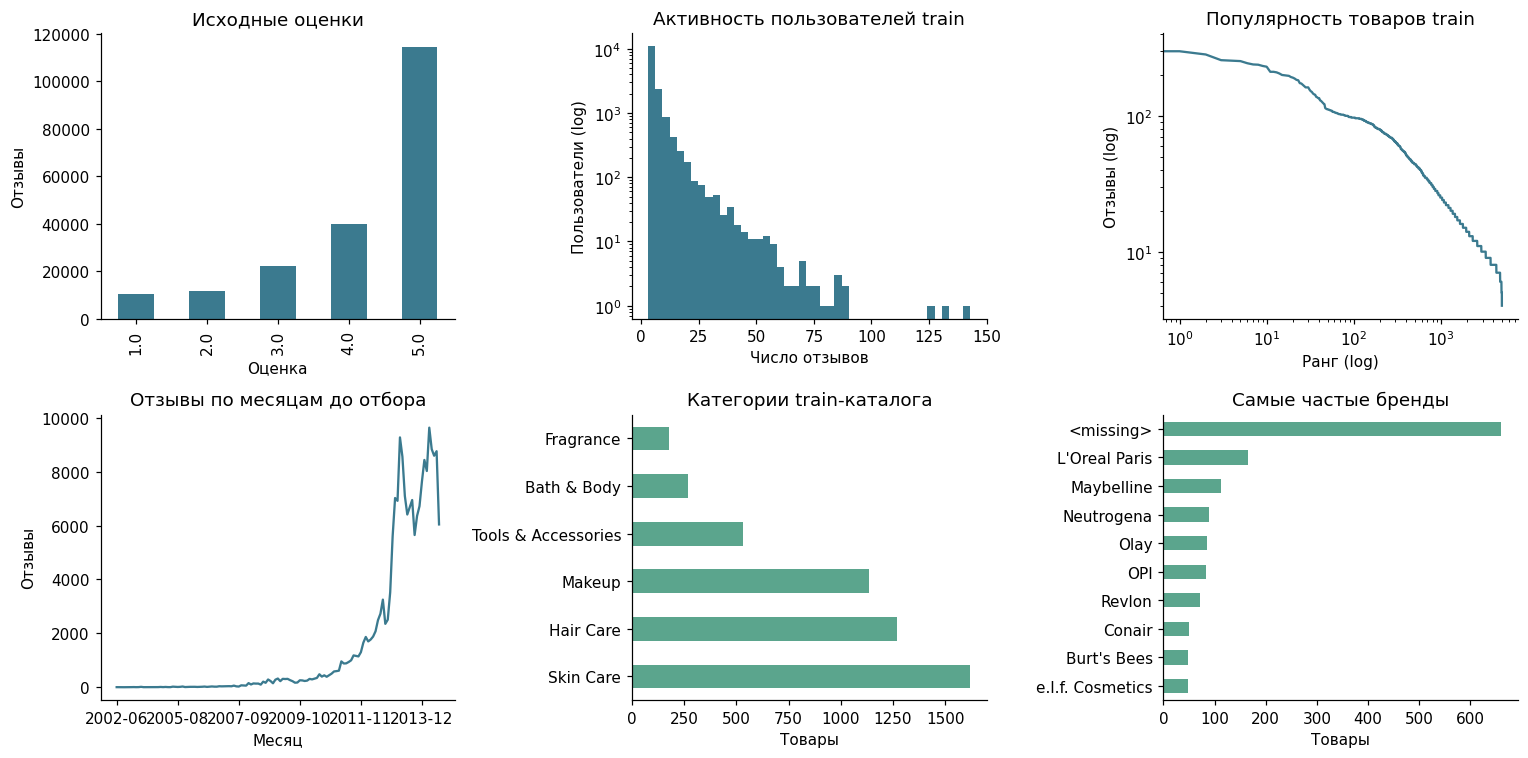

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
raw.rating.value_counts().sort_index().plot.bar(ax=axes[0, 0], color='#3b7a8f')
axes[0, 0].set(title='Исходные оценки', xlabel='Оценка', ylabel='Отзывы')
train.groupby('user').size().plot.hist(bins=45, logy=True, ax=axes[0, 1], color='#3b7a8f')
axes[0, 1].set(title='Активность пользователей train', xlabel='Число отзывов', ylabel='Пользователи (log)')
train.groupby('item').size().sort_values(ascending=False).reset_index(drop=True).plot(ax=axes[0, 2], loglog=True, color='#3b7a8f')
axes[0, 2].set(title='Популярность товаров train', xlabel='Ранг (log)', ylabel='Отзывы (log)')
monthly = pd.to_datetime(clean.timestamp, unit='s', utc=True).dt.strftime('%Y-%m').value_counts().sort_index()
monthly.plot(ax=axes[1, 0], color='#3b7a8f')
axes[1, 0].set(title='Отзывы по месяцам до отбора', xlabel='Месяц', ylabel='Отзывы')
meta.category.map(lambda paths: paths[0][1] if paths and len(paths[0]) > 1 else '<missing>').value_counts().head(10).plot.barh(ax=axes[1, 1], color='#5ba58d')
axes[1, 1].set(title='Категории train-каталога', xlabel='Товары', ylabel='')
meta.brand.replace('', '<missing>').value_counts().head(10).sort_values().plot.barh(ax=axes[1, 2], color='#5ba58d')
axes[1, 2].set(title='Самые частые бренды', xlabel='Товары', ylabel='')
plt.tight_layout()
plt.show()


In [4]:
metadata_eda = pd.DataFrame({
    'field': ['metadata row', 'brand', 'category path', 'title'],
    'coverage': [meta.has_metadata.mean(), meta.brand.ne('').mean(),
                 meta.category.map(bool).mean(), meta.title.ne('').mean()]})
display(metadata_eda)
activity = train.groupby('user').size()
popularity = train.groupby('item').size()
display(pd.DataFrame({'train user activity': activity.describe(),
                      'train item popularity': popularity.describe()}))
print('Доля отзывов у 1% самых популярных товаров train:',
      round(popularity.nlargest(max(1, int(len(items) * .01))).sum() / len(train), 4))


Доля отзывов у 1% самых популярных товаров train: 0.0881


,field,coverage
0,metadata row,1.0000
1,brand,0.8680
2,category path,1.0000
3,title,0.9994


,train user activity,train item popularity
count,15416.000000,5000.00000
mean,6.721004,20.72220
std,6.370235,25.36605
min,3.000000,4.00000
25%,4.000000,8.00000
50%,5.000000,12.00000
75%,7.000000,21.00000
max,143.000000,326.00000


Распределения активности и популярности имеют длинный хвост, поэтому одного общего среднего недостаточно. Отбор каталога повышает плотность и облегчает задачу; результаты нельзя переносить на редкие новые товары. Все оставшиеся отзывы сохраняются, включая низкие оценки: они полезны FM и кастомному ALS.

Бренд и категории трактуем как постоянные свойства уже существовавшего в train товара, известные из карточки на момент рекомендации. Источник не хранит исторические версии карточек: это допущение эксперимента. Динамические метаданные исключены. При нескольких путях категорий используем первый, чтобы не усложнять схему признаков и обучение.

## 3. Протокол оценки

- Train: $t < T_1$. Validation: $T_1 le t < T_2$. Test: $t ge T_2$. Даты в UTC; события одного дня не разделяются.
- Каталог и отображения ID строятся по train и фиксируются до конца эксперимента. Новые пользователи и товары исключаются: оцениваем warm-start. Число исключённых строк приведено выше. Популярностный fallback для cold-start здесь не оценивается.
- При подборе обучаемся только на train. После выбора настроек переобучаемся на train + validation и один раз оцениваем test.
- На каждой стадии оцениваем всех фиксированных warm-пользователей с хотя бы одним релевантным товаром в соответствующем окне. Наборы пользователей между validation и test могут различаться; **внутри стадии они одинаковы для всех методов**. Пользователей без релевантных событий не включаем, так как для них Recall не определён.
- Кандидаты — **весь фиксированный каталог train**, кроме всех уже встречавшихся пользователю товаров независимо от оценки. На validation исключаем train, на test — train + validation. Негативных кандидатов при оценке не сэмплируем. После дедупликации один товар не может повториться в истории и holdout.
- Все рекомендации выдаются в начале окна, история внутри окна не обновляется. Временные рекомендации не знают дату будущего отзыва. При равенстве score порядок определяется внутренним item ID (лексикографический ASIN).
- Разные таргеты обучения не меняют релевантность: для **всех** моделей на validation/test это `rating >= 4`.

Для пользователя $u$ с релевантными товарами $R_u$ и списком $L_u$:

$$\operatorname{Recall@10}(u)=\frac{|L_u\cap R_u|}{|R_u|},\qquad
\operatorname{NDCG@10}(u)=\frac{\sum_{j=1}^{10}\mathbb{1}[L_{uj}\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

Усредняем по пользователям (macro). Coverage — доля каталога, встретившаяся хотя бы в одной десятке. Для абляций считаем парный bootstrap по test-пользователям: 2000 повторов, seed 42; интервалы условны на одном обучении и не отражают вариативность обучения по seed.

In [5]:
split_table = []
for name, frame in [('train', train), ('validation', valid), ('test', test)]:
    truth = ground_truth(frame)
    split_table.append({'split': name, 'rows': len(frame), 'users_with_events': frame.user.nunique(),
                        'positive_rows': int((frame.rating >= 4).sum()), 'eval_users': len(truth),
                        'start': pd.to_datetime(frame.timestamp.min(), unit='s', utc=True),
                        'end': pd.to_datetime(frame.timestamp.max(), unit='s', utc=True)})
display(pd.DataFrame(split_table))
x_train = matrix(train, shape)
x_known_test = matrix(pd.concat([train, valid]), shape)
for history, holdout in [(x_train, valid), (x_known_test, test)]:
    assert np.all(np.asarray(history[holdout.user.to_numpy(), holdout.item.to_numpy()]).ravel() == 0)
    assert history.shape == shape
print('Пересечений истории с holdout нет; минимальное число кандидатов на test:',
      shape[1] - np.diff(x_known_test.indptr).max())


Пересечений истории с holdout нет; минимальное число кандидатов на test: 4857


,split,rows,users_with_events,positive_rows,eval_users,start,end
0,train,103611,15416,80331,15253,2002-06-16 00:00:00+00:00,2013-12-26 00:00:00+00:00
1,validation,5885,3107,4410,2564,2013-12-27 00:00:00+00:00,2014-04-08 00:00:00+00:00
2,test,3689,2148,2733,1703,2014-04-09 00:00:00+00:00,2014-07-22 00:00:00+00:00


## 4. Модели и подбор

### ItemKNN — `models/itemknn.py`

Бинарная матрица $A_{ui}=1$ для любого обучающего отзыва. Косинусная близость с уменьшением веса ненадёжных совпадений:

$$s_{ij}=\frac{A_{:i}^{\mathsf T}A_{:j}}{\|A_{:i}\|\|A_{:j}\|}\frac{n_{ij}}{n_{ij}+\beta},\quad s_{ii}=0.$$

Для каждого целевого товара сохраняем $k$ ближайших исходных соседей. Score: $\hat r_{uj}=\sum_{i\in I_u}s_{ij}$. Обучение — собственное вычисление co-occurrence и выбор соседей, без библиотечного KNN.

### iALS — `models/ials.py`

Для наблюдавшихся пар $p_{ui}=1$, $c_{ui}=1+\alpha$; для остальных $p_{ui}=0$, $c_{ui}=1$. Любой отзыв — сигнал знакомства с товаром, поэтому даже низкая оценка в этой базовой постановке означает наблюдавшееся взаимодействие.

$$\min_{X,Y}\sum_{u,i}c_{ui}(p_{ui}-x_u^{\mathsf T}y_i)^2+
\lambda(\|X\|_F^2+\|Y\|_F^2).$$

Попеременно решаем нормальные уравнения:

$$x_u=(Y^\mathsf TY+\alpha\sum_{i\in I_u}y_i y_i^{\mathsf T}+\lambda I)^{-1}
(1+\alpha)\sum_{i\in I_u}p_{ui}y_i.$$

Обновление товаров симметрично. Матрицу не инвертируем: используем `numpy.linalg.solve`. Ранжируем по $x_u^\mathsf Ty_i$.

### EASE — `models/ease.py`

$$\min_B\|A-AB\|_F^2+\lambda\|B\|_F^2,\quad \operatorname{diag}(B)=0.$$

Пусть $P=(A^\mathsf TA+\lambda I)^{-1}$, тогда $B_{ij}=-P_{ij}/P_{jj}$ для $i\ne j$, диагональ нулевая. Score: $AB$. Решение получаем собственной реализацией формулы через разложение Холецкого. Это алгебраическая операция SciPy, не готовая модель. Память и время зависят квадратично/кубически от размера каталога, поэтому каталог ограничен по train.

### FM — `models/fm.py`

Каждая пара кодируется пятью one-hot полями: user ID, item ID, бренд, категория 1 и категория 2. Области индексов полей не пересекаются. Формула второго порядка:

$$\hat y(z)=w_0+\sum_jw_jz_j+\frac12\sum_{f=1}^d\left[(\sum_jv_{jf}z_j)^2-\sum_jv_{jf}^2z_j^2\right].$$

Обучаем логистическую функцию потерь вручную выведенными градиентами и AdaGrad. Наблюдаемые оценки 4–5 имеют label 1, оценки 1–3 — label 0. На каждый положительный отзыв в каждой эпохе равномерно сэмплируем 3 неизвестных пользователю товара с label 0; все известные пары из отрицательного сэмплирования исключаются. Это приближение: неизвестный товар может быть подходящим, но не просмотренным.

Оценка потерь усредняется по обучающим примерам. В SGD добавляется L2 для активных параметров (масштаб `reg / batch_size`, фиксированная константа `1e-4`). Ранжируем по логиту, монотонному вероятности. Обучение FM полностью на NumPy; аналитические градиенты и оптимизированный score отдельно проверяются тестами.

### ALS с рейтингом и давностью — `models/custom_als.py`

Для обучающей пары с оценкой $r_{ui}$ и возрастом отзыва $a_{ui}=(T_{\mathrm{recommend}}-t_{ui})/86400$ предлагаем целевой сигнал:

$$p^*_{ui}=\frac{r_{ui}-3}{2}\left(\frac12+\frac12\exp\left[-\ln2\,\frac{a_{ui}}{H}\right]\right).$$

Для ненаблюдавшейся пары $p^*_{ui}=0$. Оценки 1–2 дают отрицательный сигнал, 3 — нейтральный, 4–5 — положительный. Давность снижает модуль сигнала, но не уничтожает старые предпочтения: множитель ограничен снизу 0.5. Пара с оценкой 3 остаётся наблюдавшейся и имеет повышенный confidence, даже при нулевом таргете.

Это **изменение таргета**, а не только confidence: $c_{ui}$, регуляризация, размерность и число итераций совпадают с выбранным базовым iALS. Используем те же нормальные уравнения, подставляя $p^*$ вместо $p$. Для validation возраст считаем от $T_1$, для финального обучения — от $T_2$, никогда от даты holdout-события.

Подбираем только $H\in\{90,365\}$ дней на validation, а остальные параметры берём из победившего базового iALS. Так сравнение изолирует смену таргета. Для анализа временной части дополнительно обучим RatingALS с $H=\infty$: остаётся сигнал оценки без затухания.

### Пространство поиска

Небольшая сетка по две конфигурации на модель, бюджет фиксирован до вычисления результатов. При равенстве NDCG выбираем первую конфигурацию. У всех моделей одинаковые train, пользователи и кандидаты. Test не участвует ни в выборе параметров, ни в ранней остановке. Для FM фиксируем число эпох 12, размер minibatch 2048, три негатива и seed 42; для ALS seed 42, 12 итераций.

In [6]:
display(pd.DataFrame([{'model': name, 'configuration': i + 1, 'parameters': params}
                      for name, grid in SEARCH.items() for i, params in enumerate(grid)]))
print('CustomALS: параметры выбранного iALS; half_life ∈ {90, 365}.')
print('Основная метрика: NDCG@10. Финальный test ещё не оценивался.')


CustomALS: параметры выбранного iALS; half_life ∈ {90, 365}.
Основная метрика: NDCG@10. Финальный test ещё не оценивался.


,model,configuration,parameters
0,ItemKNN,1,"{'neighbors': 30, 'shrink': 10}"
1,ItemKNN,2,"{'neighbors': 100, 'shrink': 30}"
2,iALS,1,"{'factors': 32, 'reg': 10.0, 'alpha': 20.0, 'i..."
3,iALS,2,"{'factors': 64, 'reg': 20.0, 'alpha': 20.0, 'i..."
4,EASE,1,{'reg': 100.0}
5,EASE,2,{'reg': 500.0}
6,FM,1,"{'factors': 16, 'lr': 0.04, 'epochs': 12}"
7,FM,2,"{'factors': 32, 'lr': 0.04, 'epochs': 12}"


In [7]:
validation_results, chosen, actual_search = tune(train, valid, shape, features)
display(validation_results.sort_values(['model', 'NDCG@10'], ascending=[True, False]).reset_index(drop=True))
display(pd.DataFrame([{'model': name, 'selected_parameters': params} for name, params in chosen.items()]))
Path('results/search_space.json').write_text(json.dumps(actual_search, indent=2))
Path('results/data_summary.json').write_text(json.dumps({**report, **metadata_report, 'hashes': hashes}, indent=2))


ItemKNN {'neighbors': 30, 'shrink': 10} {'Recall@10': 0.04279, 'NDCG@10': 0.02714, 'Coverage@10': 0.7674, 'eval_users': 2564}
ItemKNN {'neighbors': 100, 'shrink': 30} {'Recall@10': 0.04317, 'NDCG@10': 0.02729, 'Coverage@10': 0.7414, 'eval_users': 2564}
iALS {'factors': 32, 'reg': 10.0, 'alpha': 20.0, 'iterations': 12} {'Recall@10': 0.04677, 'NDCG@10': 0.02793, 'Coverage@10': 0.1838, 'eval_users': 2564}
iALS {'factors': 64, 'reg': 20.0, 'alpha': 20.0, 'iterations': 12} {'Recall@10': 0.04911, 'NDCG@10': 0.02964, 'Coverage@10': 0.27, 'eval_users': 2564}
EASE {'reg': 100.0} {'Recall@10': 0.0479, 'NDCG@10': 0.02987, 'Coverage@10': 0.616, 'eval_users': 2564}
EASE {'reg': 500.0} {'Recall@10': 0.04896, 'NDCG@10': 0.03072, 'Coverage@10': 0.5668, 'eval_users': 2564}
FM {'factors': 16, 'lr': 0.04, 'epochs': 12} {'Recall@10': 0.01883, 'NDCG@10': 0.01106, 'Coverage@10': 0.0318, 'eval_users': 2564}
FM {'factors': 32, 'lr': 0.04, 'epochs': 12} {'Recall@10': 0.02146, 'NDCG@10': 0.01311, 'Coverage@10':

,model,params,fit_seconds,Recall@10,NDCG@10,Coverage@10,eval_users
0,CustomALS,"{""alpha"": 20.0, ""factors"": 64, ""half_life"": 90...",16.466801,0.041256,0.025336,0.2442,2564
1,CustomALS,"{""alpha"": 20.0, ""factors"": 64, ""half_life"": 36...",15.270063,0.041670,0.025081,0.2434,2564
2,EASE,"{""reg"": 500.0}",3.183725,0.048960,0.030724,0.5668,2564
3,EASE,"{""reg"": 100.0}",3.902049,0.047902,0.029866,0.6160,2564
4,FM,"{""epochs"": 12, ""factors"": 32, ""lr"": 0.04}",30.191887,0.021459,0.013109,0.0490,2564
5,FM,"{""epochs"": 12, ""factors"": 16, ""lr"": 0.04}",15.652574,0.018828,0.011057,0.0318,2564
6,ItemKNN,"{""neighbors"": 100, ""shrink"": 30}",0.359242,0.043167,0.027292,0.7414,2564
7,ItemKNN,"{""neighbors"": 30, ""shrink"": 10}",0.226770,0.042793,0.027135,0.7674,2564
8,iALS,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 1...",30.620653,0.049111,0.029638,0.2700,2564
9,iALS,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 1...",11.599365,0.046768,0.027928,0.1838,2564


,model,selected_parameters
0,ItemKNN,"{'neighbors': 100, 'shrink': 30}"
1,iALS,"{'alpha': 20.0, 'factors': 64, 'iterations': 1..."
2,EASE,{'reg': 500.0}
3,FM,"{'epochs': 12, 'factors': 32, 'lr': 0.04}"
4,CustomALS,"{'alpha': 20.0, 'factors': 64, 'half_life': 90..."


### Выбранные параметры

| Модель | Параметры |
|---|---|
| ItemKNN | `neighbors=100`, `shrink=30` |
| iALS | `alpha=20.0`, `factors=64`, `iterations=12`, `reg=20.0` |
| EASE | `reg=500.0` |
| FM | `epochs=12`, `factors=32`, `lr=0.04`, `reg=0.0001`, `negatives=3`, `batch_size=2048` |
| CustomALS | `alpha=20.0`, `factors=64`, `half_life=90`, `iterations=12`, `reg=20.0` |

У iALS, FM и CustomALS `seed=42`; генератор сэмплирования FM использует `seed + 1`. Параметры выбраны по validation NDCG@10.

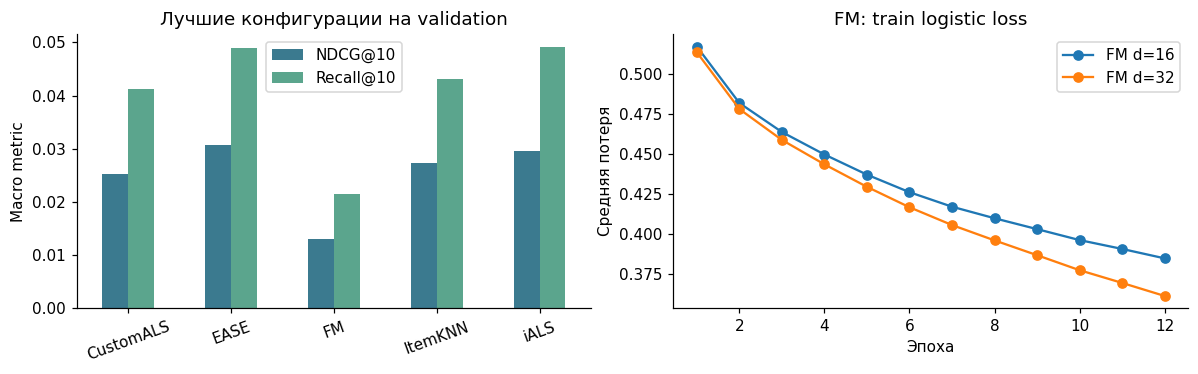

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
best_valid = validation_results.loc[validation_results.groupby('model')['NDCG@10'].idxmax()].set_index('model')
best_valid[['NDCG@10', 'Recall@10']].plot.bar(ax=axes[0], color=['#3b7a8f', '#5ba58d'])
axes[0].set(title='Лучшие конфигурации на validation', ylabel='Macro metric', xlabel='')
axes[0].tick_params(axis='x', rotation=20)
for d in [16, 32]:
    losses = json.loads(Path(f'results/fm_loss_{d}.json').read_text())
    axes[1].plot(np.arange(1, len(losses) + 1), losses, marker='o', label=f'FM d={d}')
axes[1].set(title='FM: train logistic loss', xlabel='Эпоха', ylabel='Средняя потеря')
axes[1].legend()
plt.tight_layout()
plt.show()


## 5. Финальное сравнение на test

Параметры выбраны и сохранены. Переобучаем каждую модель на train + validation. Каталог и набор пользователей остаются фиксированными по исходному train.

Заранее заданные абляции:

1. **FM_ID_only**: те же выбранные параметры, seed и негативы, но без бренда и категорий. Эта абляция оценивает добавление метаданных при одинаковом бюджете, а не максимум отдельно подобранной ID-only модели.
2. **RatingALS**: те же параметры кастомного ALS, но без затухания, $H=\infty$. Сравнение показывает эффект временного множителя при выбранных настройках.

Абляции не участвуют в выборе победителя среди пяти основных моделей. После просмотра test параметры не меняем.

In [9]:
train_valid = pd.concat([train, valid], ignore_index=True)
test_results, bootstrap = final_evaluation(train_valid, test, shape, features, chosen)
main_names = ['ItemKNN', 'iALS', 'EASE', 'FM', 'CustomALS']
main_results = test_results[test_results.model.isin(main_names)].sort_values('NDCG@10', ascending=False)
display(main_results[['model', 'NDCG@10', 'Recall@10', 'Coverage@10', 'fit_seconds', 'ranking_seconds', 'params']].reset_index(drop=True))
display(test_results[~test_results.model.isin(main_names)][['model', 'NDCG@10', 'Recall@10', 'Coverage@10', 'params']])
display(pd.DataFrame(bootstrap).T)


TEST ItemKNN {'Recall@10': 0.03907, 'NDCG@10': 0.02344, 'Coverage@10': 0.6444, 'eval_users': 1703}
TEST iALS {'Recall@10': 0.04413, 'NDCG@10': 0.02763, 'Coverage@10': 0.2502, 'eval_users': 1703}
TEST EASE {'Recall@10': 0.04163, 'NDCG@10': 0.02784, 'Coverage@10': 0.4616, 'eval_users': 1703}
TEST FM {'Recall@10': 0.02102, 'NDCG@10': 0.013, 'Coverage@10': 0.0468, 'eval_users': 1703}
TEST CustomALS {'Recall@10': 0.03822, 'NDCG@10': 0.02394, 'Coverage@10': 0.2256, 'eval_users': 1703}
TEST FM_ID_only {'Recall@10': 0.01871, 'NDCG@10': 0.00905, 'Coverage@10': 0.0058, 'eval_users': 1703}
TEST RatingALS {'Recall@10': 0.03447, 'NDCG@10': 0.02196, 'Coverage@10': 0.2354, 'eval_users': 1703}


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds,ranking_seconds,params
0,EASE,0.027837,0.041628,0.4616,3.671895,2.214859,"{""reg"": 500.0}"
1,iALS,0.027632,0.044133,0.2502,14.866584,0.772448,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 1..."
2,CustomALS,0.023940,0.038221,0.2256,13.258594,0.741500,"{""alpha"": 20.0, ""factors"": 64, ""half_life"": 90..."
3,ItemKNN,0.023442,0.039068,0.6444,0.354707,0.359493,"{""neighbors"": 100, ""shrink"": 30}"
4,FM,0.012997,0.021023,0.0468,27.582442,1.124330,"{""epochs"": 12, ""factors"": 32, ""lr"": 0.04}"


,model,NDCG@10,Recall@10,Coverage@10,params
5,FM_ID_only,0.009047,0.018708,0.0058,"{""epochs"": 12, ""factors"": 32, ""lr"": 0.04, ""use..."
6,RatingALS,0.021964,0.034469,0.2354,"{""alpha"": 20.0, ""factors"": 64, ""half_life"": In..."


,difference,lower_95,upper_95,users
CustomALS - iALS,-0.003692,-0.008766,0.001509,1703.0
FM - FM_ID_only,0.003950,0.000707,0.007329,1703.0
CustomALS - RatingALS,0.001976,-0.000700,0.004850,1703.0


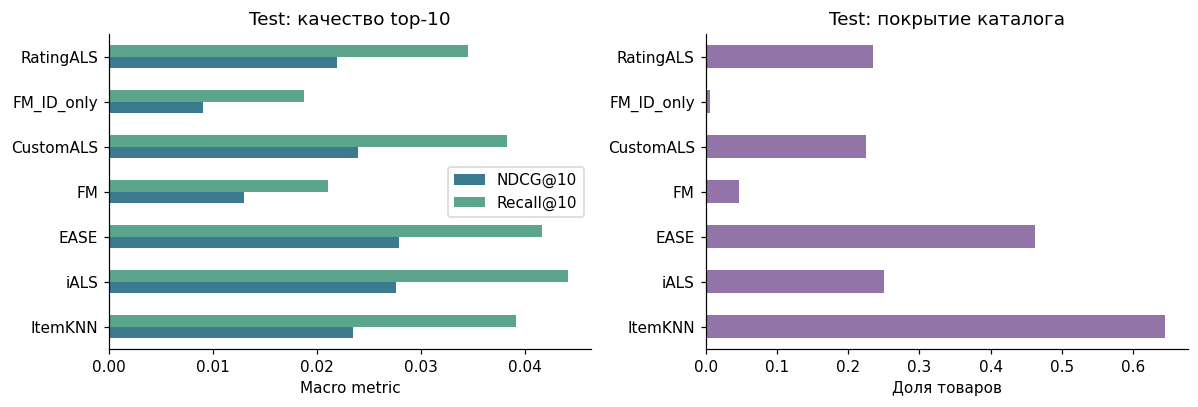

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot = test_results.set_index('model')
plot[['NDCG@10', 'Recall@10']].plot.barh(ax=axes[0], color=['#3b7a8f', '#5ba58d'])
axes[0].set(title='Test: качество top-10', xlabel='Macro metric', ylabel='')
plot['Coverage@10'].plot.barh(ax=axes[1], color='#9274a8')
axes[1].set(title='Test: покрытие каталога', xlabel='Доля товаров', ylabel='')
plt.tight_layout()
plt.show()


### Примеры персональных рекомендаций

Покажем первых трёх test-пользователей по внутреннему ID, не выбирая их по качеству рекомендаций. Для компактности у первого пользователя выводим top-10 двух методов. В `results/recommendations.csv` сохранены списки всех методов для трёх пользователей. `hit` означает попадание в положительный test, отсутствие hit не доказывает, что товар не подходит.

In [11]:
examples = pd.read_csv('results/recommendations.csv')
example_user = examples.user.min()
winner = main_results.iloc[0]['model']
lookup = meta[['title', 'brand']].copy()
lookup['item'] = np.arange(len(meta))
example_names = list(dict.fromkeys([winner, 'FM']))
shown = examples[(examples.user == example_user) & examples.model.isin(example_names)]
display(shown.merge(lookup, on='item')[['model', 'user', 'rank', 'title', 'brand', 'relevant']].rename(columns={'relevant': 'hit'}))


,model,user,rank,title,brand,hit
0,EASE,9,1,"Revlon ColorStay Makeup, Combination/Oily Skin...",Revlon,0
1,EASE,9,2,e.l.f. Essential Eyelid Primer-7501 Sheer,e.l.f. Cosmetics,0
2,EASE,9,3,"Maybelline 24 Hour Eyeshadow, Too Cool, 0.14 O...",Maybelline,0
3,EASE,9,4,Maybelline Dream Fresh BB Cream 100 Light Shee...,Maybelline,0
4,EASE,9,5,Maybelline New York Dream Matte Mousse Foundat...,Maybelline,0
5,EASE,9,6,Maybelline New York The Colossal Volum' Expres...,Maybelline,0
6,EASE,9,7,Maybelline New York Expert Wear Eyeshadow Quad...,Maybelline,0
7,EASE,9,8,"Maybelline New York Fit Me! Foundation, 120 Cl...",Maybelline,0
8,EASE,9,9,CLEAR SCALP & HAIR BEAUTY Volumizing Root Boos...,Clear,0
9,EASE,9,10,Maybelline New York Color Whisper by ColorSens...,Maybelline,0


## 6. Выводы

Числа ниже формируются из полученных таблиц. Победитель выбирается среди пяти основных методов; абляции служат для проверки двух отдельных гипотез.

In [12]:
scores = test_results.set_index('model')
best = main_results.iloc[0]
lines = [f"Лучший из пяти методов по test NDCG@10 — **{best['model']}**: "
         f"NDCG@10 = **{best['NDCG@10']:.5f}**, Recall@10 = **{best['Recall@10']:.5f}**. "
         f"Параметры: `{best['params']}`."]
lines.append('Разрыв между EASE и iALS по NDCG@10 мал; первое место в этой таблице само по себе не доказывает устойчивого превосходства на других периодах или seed.')
for label, left, right in [('Метаданные FM', 'FM', 'FM_ID_only'),
                           ('Кастомный таргет ALS', 'CustomALS', 'iALS'),
                           ('Затухание по времени', 'CustomALS', 'RatingALS')]:
    key = {'Метаданные FM': 'FM - FM_ID_only', 'Кастомный таргет ALS': 'CustomALS - iALS',
           'Затухание по времени': 'CustomALS - RatingALS'}[label]
    ci = bootstrap[key]
    sign = 'выше' if ci['difference'] > 0 else ('ниже' if ci['difference'] < 0 else 'на том же уровне')
    evidence = ('Интервал включает ноль: устойчивое различие по этой оценке не подтверждено.'
                if ci['lower_95'] <= 0 <= ci['upper_95'] else
                'Интервал не включает ноль для этой фиксированной пары обученных моделей.')
    lines.append(f"**{label}.** NDCG@10 {left} {sign}, чем {right}: "
                 f"{scores.loc[left, 'NDCG@10']:.5f} против {scores.loc[right, 'NDCG@10']:.5f}; "
                 f"разность {ci['difference']:+.5f}, парный 95% интервал "
                 f"[{ci['lower_95']:+.5f}; {ci['upper_95']:+.5f}]. {evidence}")
broad = scores['Coverage@10'].idxmax()
lines.append(f"Самое широкое покрытие у **{broad}**: {scores.loc[broad, 'Coverage@10']:.2%} каталога. "
             'Покрытие не заменяет персональное качество: оно считается отдельно от релевантности.')
display(Markdown('\n\n'.join(lines)))
Path('results/conclusions.md').write_text('\n\n'.join(lines), encoding='utf-8')


Out[0]: 1080


Лучший из пяти методов по test NDCG@10 — **EASE**: NDCG@10 = **0.02784**, Recall@10 = **0.04163**. Параметры: `{"reg": 500.0}`.

Разрыв между EASE и iALS по NDCG@10 мал; первое место в этой таблице само по себе не доказывает устойчивого превосходства на других периодах или seed.

**Метаданные FM.** NDCG@10 FM выше, чем FM_ID_only: 0.01300 против 0.00905; разность +0.00395, парный 95% интервал [+0.00071; +0.00733]. Интервал не включает ноль для этой фиксированной пары обученных моделей.

**Кастомный таргет ALS.** NDCG@10 CustomALS ниже, чем iALS: 0.02394 против 0.02763; разность -0.00369, парный 95% интервал [-0.00877; +0.00151]. Интервал включает ноль: устойчивое различие по этой оценке не подтверждено.

**Затухание по времени.** NDCG@10 CustomALS выше, чем RatingALS: 0.02394 против 0.02196; разность +0.00198, парный 95% интервал [-0.00070; +0.00485]. Интервал включает ноль: устойчивое различие по этой оценке не подтверждено.

Самое широкое покрытие у **ItemKNN**: 64.44% каталога. Покрытие не заменяет персональное качество: оно считается отдельно от релевантности.

Наиболее существенные ограничения:

- Историческая выборка Beauty и отбор популярных товаров ограничивают переносимость выводов. 5-core из источника использует весь период; наша дополнительная фильтрация и все обучающие признаки зависят только от train.
- Это warm-start и отзывы, а не журнал показов/покупок. Непросмотренные товары ошибочно могут считаться отрицательными при обучении FM. В test ненаблюдавшиеся товары считаются нерелевантными для вычисления offline-метрик, хотя фактически предпочтения неизвестны.
- Метаданные — снимок. Считаем бренд и категории постоянными, но проверить их исторические изменения нельзя.
- Короткая сетка из двух вариантов не определяет предел качества методов. Результат на одном seed и одном временном разбиении; bootstrap не заменяет повторы обучения и проверку на других периодах.
- Глобальное разбиение исключает будущие взаимодействия из обучения, но сильно уменьшает число доступных test-событий после warm-start отбора. Основные метрики условны на наличии положительного отзыва в holdout; для неактивных пользователей качество не оценивалось.
- Выводы об эффекте метаданных и времени относятся к заданным абляциям, не являются причинными выводами об онлайн-конверсии.

Проверки реализации: нормальные уравнения ALS с отрицательными таргетами, constrained optimum EASE, ручная сумма взаимодействий FM, конечные разности градиента FM, косинус ItemKNN, метрики и фильтр известных товаров. Команда: `python -m unittest discover -s tests -v`.

In [13]:
source_files = sorted(list(Path('models').glob('*.py')) + [Path('data_utils.py'), Path('evaluation.py'), Path('experiment.py')])
manifest = {str(p): sha256(p) for p in source_files}
Path('results/source_hashes.json').write_text(json.dumps(manifest, indent=2))
print('Результаты сохранены. Пользователей test:', int(test_results.eval_users.iloc[0]))
assert test_results.eval_users.nunique() == 1
assert len(test_results) == 7
assert test_results[['NDCG@10', 'Recall@10', 'Coverage@10']].ge(0).all().all()
assert test_results[['NDCG@10', 'Recall@10', 'Coverage@10']].le(1).all().all()


Результаты сохранены. Пользователей test: 1703
